# AdventureWorks | Sales Analysis in Python

**End-to-end exploratory data analysis (EDA)** of sales, products, customers, and territories in the AdventureWorks2022 sample database.

**Analytical workflow:** SQL Server is used to extract relational data; **Pandas** performs aggregations, comparisons, and quality checks; **Matplotlib** presents the findings. More advanced SQL analyses are kept in the repository's `sql/` folder.

**Questions addressed:** How do sales evolve? Which products and territories drive revenue? How do individual and business customers differ? What explains the unusual June 2014 results?

## 1. Setup and Database Connection

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sqlalchemy import create_engine, text

connection_string = (
    "mssql+pyodbc://@localhost/AdventureWorks2022"
    "?driver=ODBC+Driver+18+for+SQL+Server"
    "&trusted_connection=yes"
    "&TrustServerCertificate=yes"
)
engine = create_engine(connection_string)

with engine.connect() as connection:
    total_orders = connection.execute(
        text("SELECT COUNT(*) FROM Sales.SalesOrderHeader")
    ).scalar_one()
print(f"Database connection successful — {total_orders:,} sales orders")

Database connection successful — 31,465 sales orders


## 2. Data Loading and Preparation

Extract detailed, **non-aggregated** data from SQL Server. Subsequent measures are calculated in Pandas. The data has two grains: an order header (`TotalDue`) and an order line (`LineTotal`).

In [2]:
# One row per order (header-level metrics)
query_orders = """
SELECT
    SalesOrderID,
    OrderDate,
    TotalDue,
    OnlineOrderFlag
FROM Sales.SalesOrderHeader;
"""
df_orders = pd.read_sql(query_orders, engine)
df_orders["OrderDate"] = pd.to_datetime(df_orders["OrderDate"])
df_orders["SalesYear"] = df_orders["OrderDate"].dt.year
df_orders["YearMonth"] = df_orders["OrderDate"].dt.to_period("M")
df_orders.head()

,SalesOrderID,OrderDate,TotalDue,OnlineOrderFlag,SalesYear,YearMonth
0,43659,2011-05-31,23153.2339,False,2011,2011-05
1,43660,2011-05-31,1457.3288,False,2011,2011-05
2,43661,2011-05-31,36865.8012,False,2011,2011-05
3,43662,2011-05-31,32474.9324,False,2011,2011-05
4,43663,2011-05-31,472.3108,False,2011,2011-05


In [ ]:
query_order_lines = """
SELECT
    sod.SalesOrderDetailID,
    sod.SalesOrderID,
    soh.OrderDate,
    soh.OnlineOrderFlag,
    p.Name AS ProductName,
    psc.Name AS Subcategory,
    pc.Name AS Category,
    sod.OrderQty,
    sod.LineTotal
FROM Sales.SalesOrderDetail AS sod
INNER JOIN Sales.SalesOrderHeader AS soh
    ON sod.SalesOrderID = soh.SalesOrderID
INNER JOIN Production.Product AS p
    ON sod.ProductID = p.ProductID
LEFT JOIN Production.ProductSubcategory AS psc
    ON p.ProductSubcategoryID = psc.ProductSubcategoryID
LEFT JOIN Production.ProductCategory AS pc
    ON psc.ProductCategoryID = pc.ProductCategoryID;
"""
df_order_lines = pd.read_sql(query_order_lines, engine)
df_order_lines["OrderDate"] = pd.to_datetime(df_order_lines["OrderDate"])
df_order_lines["YearMonth"] = df_order_lines["OrderDate"].dt.to_period("M")
df_order_lines.head()

,SalesOrderDetailID,SalesOrderID,OrderDate,OnlineOrderFlag,ProductName,Subcategory,Category,OrderQty,LineTotal,YearMonth
0,1,43659,2011-05-31,False,"Mountain-100 Black, 42",Mountain Bikes,Bikes,1,2024.994,2011-05
1,2,43659,2011-05-31,False,"Mountain-100 Black, 44",Mountain Bikes,Bikes,3,6074.982,2011-05
2,3,43659,2011-05-31,False,"Mountain-100 Black, 48",Mountain Bikes,Bikes,1,2024.994,2011-05
3,4,43659,2011-05-31,False,"Mountain-100 Silver, 38",Mountain Bikes,Bikes,1,2039.994,2011-05
4,5,43659,2011-05-31,False,"Mountain-100 Silver, 42",Mountain Bikes,Bikes,1,2039.994,2011-05


In [ ]:
query_customer_orders = """
SELECT
    c.CustomerID,
    c.PersonID,
    c.StoreID,
    soh.SalesOrderID,
    soh.OrderDate,
    soh.TotalDue,
    p.FirstName,
    p.LastName,
    s.Name AS StoreName
FROM Sales.Customer AS c
INNER JOIN Sales.SalesOrderHeader AS soh
    ON c.CustomerID = soh.CustomerID
LEFT JOIN Person.Person AS p
    ON c.PersonID = p.BusinessEntityID
LEFT JOIN Sales.Store AS s
    ON c.StoreID = s.BusinessEntityID;
"""
df_customer_orders = pd.read_sql(query_customer_orders, engine)
df_customer_orders["OrderDate"] = pd.to_datetime(df_customer_orders["OrderDate"])
df_customer_orders["CustomerType"] = np.where(
    df_customer_orders["StoreID"].notna(), "Store", "Person"
)
df_customer_orders["CustomerName"] = np.where(
    df_customer_orders["StoreID"].notna(),
    df_customer_orders["StoreName"],
    (df_customer_orders["FirstName"].fillna("") + " " +
     df_customer_orders["LastName"].fillna("")).str.strip(),
)

df_customers = (
    df_customer_orders
    .groupby(["CustomerID", "CustomerType", "CustomerName"])
    .agg(
        NumberOfOrders=("SalesOrderID", "nunique"),
        Revenue=("TotalDue", "sum"),
        AverageOrderValue=("TotalDue", "mean"),
        FirstOrderDate=("OrderDate", "min"),
        LastOrderDate=("OrderDate", "max"),
    )
    .reset_index()
)
df_customers.head()

,CustomerID,CustomerType,CustomerName,NumberOfOrders,Revenue,AverageOrderValue,FirstOrderDate,LastOrderDate
0,11000,Person,Jon Yang,3,9115.1341,3038.378033,2011-06-21,2013-10-03
1,11001,Person,Eugene Huang,3,7054.1875,2351.395833,2011-06-17,2014-05-12
2,11002,Person,Ruben Torres,3,8966.0143,2988.671433,2011-06-09,2013-07-26
3,11003,Person,Christy Zhu,3,8993.9155,2997.971833,2011-05-31,2013-10-10
4,11004,Person,Elizabeth Johnson,3,9056.5911,3018.863700,2011-06-25,2013-10-01


In [ ]:
# One row per order, including geographic attributes
query_geography = """
SELECT
    soh.SalesOrderID,
    soh.OrderDate,
    soh.TotalDue,
    st.Name AS Territory,
    st.CountryRegionCode,
    st.[Group] AS Region
FROM Sales.SalesOrderHeader AS soh
INNER JOIN Sales.SalesTerritory AS st
    ON soh.TerritoryID = st.TerritoryID;
"""
df_geography = pd.read_sql(query_geography, engine)
df_geography.head()

,SalesOrderID,OrderDate,TotalDue,Territory,CountryRegionCode,Region
0,43659,2011-05-31,23153.2339,Southeast,US,North America
1,43660,2011-05-31,1457.3288,Southeast,US,North America
2,43661,2011-05-31,36865.8012,Canada,CA,North America
3,43662,2011-05-31,32474.9324,Canada,CA,North America
4,43663,2011-05-31,472.3108,Southwest,US,North America


## 3. Data Quality Checks

Check uniqueness, missing values, sign of monetary metrics, and date coverage **before** interpreting trends. A separate customer table is built from customer-order records, so each `CustomerID` appears only once.

In [30]:
print("Orders:", len(df_orders))
print("Duplicate SalesOrderIDs:", df_orders["SalesOrderID"].duplicated().sum())
print("Missing order values:\n", df_orders.isna().sum())
print("Non-positive TotalDue:", (df_orders["TotalDue"] <= 0).sum())
print("Date range:", df_orders["OrderDate"].min().date(), "to", df_orders["OrderDate"].max().date())

print("\nOrder lines:", len(df_order_lines))
print("Duplicate line IDs:", df_order_lines["SalesOrderDetailID"].duplicated().sum())
print("Unassigned product categories:", df_order_lines["Category"].isna().sum())

print("\nCustomers with sales:", len(df_customers))
print("Duplicate CustomerIDs:", df_customers["CustomerID"].duplicated().sum())
print("Missing customer values:\n", df_customers.isna().sum())
print("Non-positive customer revenue:", (df_customers["Revenue"] <= 0).sum())
print("Customer types:\n", df_customers["CustomerType"].value_counts())

Orders: 31465
Duplicate SalesOrderIDs: 0
Missing order values:
 SalesOrderID       0
OrderDate          0
TotalDue           0
OnlineOrderFlag    0
SalesYear          0
YearMonth          0
dtype: int64
Non-positive TotalDue: 0
Date range: 2011-05-31 to 2014-06-30

Order lines: 121317
Duplicate line IDs: 0
Unassigned product categories: 0

Customers with sales: 19119
Duplicate CustomerIDs: 0
Missing customer values:
 CustomerID           0
CustomerType         0
CustomerName         0
NumberOfOrders       0
Revenue              0
AverageOrderValue    0
FirstOrderDate       0
LastOrderDate        0
dtype: int64
Non-positive customer revenue: 0
Customer types:
 CustomerType
Person    18484
Store       635
Name: count, dtype: int64


**Quality assessment (original run):** 31,465 orders, 19,119 customers with sales, no duplicate order/customer identifiers, no missing core customer/order values, and no non-positive `TotalDue` values. The date window is **May 31, 2011–June 30, 2014**; both boundary years are partial. Re-running the cell above also verifies product-line integrity.

## 4. Temporal Sales Analysis

Use order-level **`SalesOrderHeader.TotalDue`** for revenue and order analysis. Annual totals for 2011 and 2014 are **partial-year totals**, not directly comparable with complete years.

In [7]:
df_yearly = (
    df_orders.groupby("SalesYear")
    .agg(
        NumberOfOrders=("SalesOrderID", "nunique"),
        Revenue=("TotalDue", "sum"),
        AverageOrderValue=("TotalDue", "mean"),
    )
    .reset_index()
)
df_yearly

,SalesYear,NumberOfOrders,Revenue,AverageOrderValue
0,2011,1607,1.415570e+07,8808.773818
1,2012,3915,3.767570e+07,9623.422813
2,2013,14182,4.896589e+07,3452.678604
3,2014,11761,2.241950e+07,1906.257828


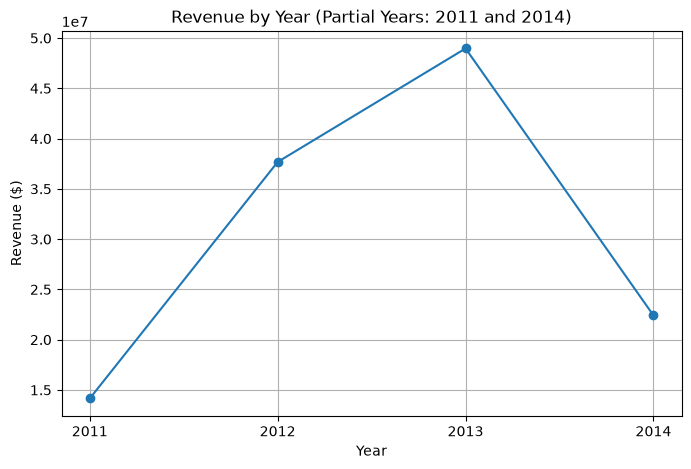

In [8]:
plt.figure(figsize=(8, 5))

plt.plot(
    df_yearly["SalesYear"],
    df_yearly["Revenue"],
    marker="o"
)
plt.title("Revenue by Year (Partial Years: 2011 and 2014)")
plt.xlabel("Year")
plt.ylabel("Revenue ($)")
plt.xticks(df_yearly["SalesYear"])
plt.grid(True)
plt.show()

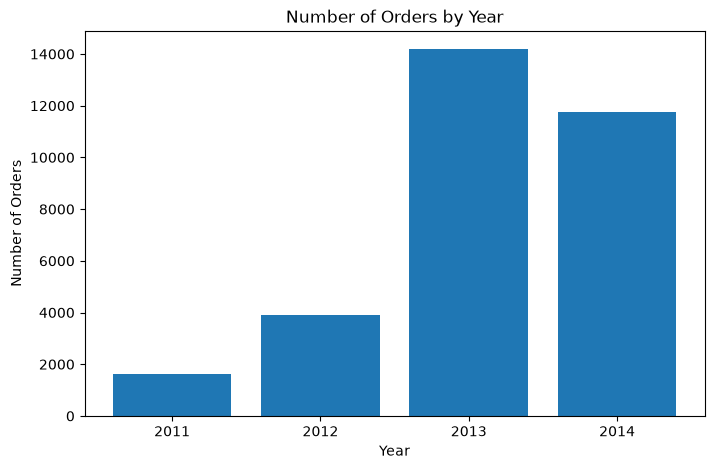

In [9]:
plt.figure(figsize=(8, 5))
plt.bar(df_yearly["SalesYear"].astype(str), df_yearly["NumberOfOrders"])
plt.title("Number of Orders by Year")
plt.xlabel("Year")
plt.ylabel("Number of Orders")
plt.show()

In [10]:
df_monthly_sales = (
    df_orders.groupby("YearMonth")
    .agg(
        NumberOfOrders=("SalesOrderID", "nunique"),
        Revenue=("TotalDue", "sum"),
        AverageOrderValue=("TotalDue", "mean"),
    )
    .reset_index()
)
df_monthly_sales["Month"] = df_monthly_sales["YearMonth"].dt.to_timestamp()
df_monthly_sales.tail(10)

,YearMonth,NumberOfOrders,Revenue,AverageOrderValue,Month
28,2013-09,1791,5.083505e+06,2838.361439,2013-09-01
29,2013-10,1968,5.374376e+06,2730.882084,2013-10-01
30,2013-11,2103,3.694668e+06,1756.855920,2013-11-01
31,2013-12,2050,4.560577e+06,2224.671754,2013-12-01
32,2014-01,2141,4.798028e+06,2241.021892,2014-01-01
33,2014-02,1756,1.478213e+06,841.807114,2014-02-01
34,2014-03,2399,8.097036e+06,3375.171452,2014-03-01
35,2014-04,2115,1.985886e+06,938.953262,2014-04-01
36,2014-05,2411,6.006183e+06,2491.158528,2014-05-01
37,2014-06,939,5.415148e+04,57.669306,2014-06-01


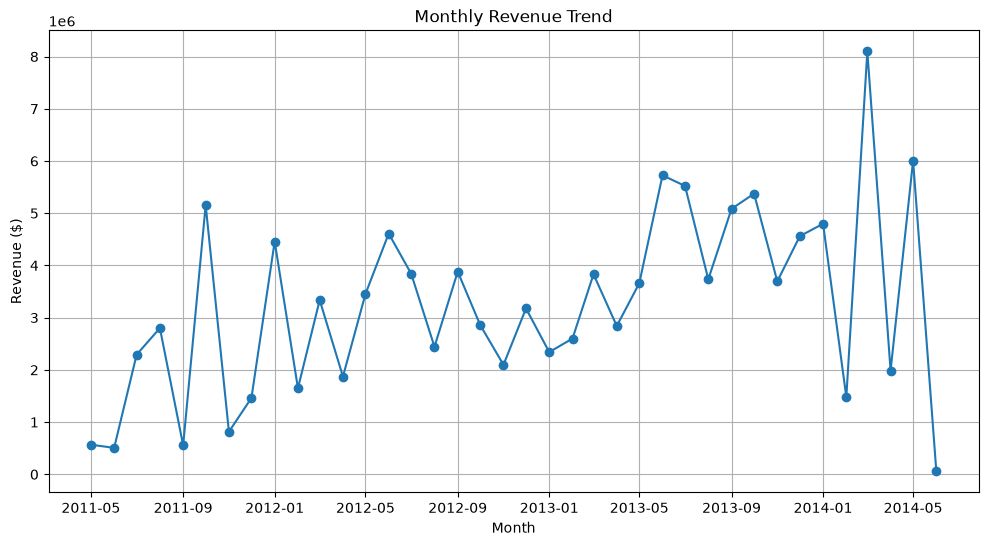

In [11]:
plt.figure(figsize=(12, 6))

plt.plot(
    df_monthly_sales["Month"],
    df_monthly_sales["Revenue"],
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue ($)")
plt.grid(True)

plt.show()

### 4.1 Investigating the June 2014 anomaly

The monthly plot shows an exceptional drop in June 2014. Instead of assuming the month is missing, investigate order activity, category mix, and online/non-online order composition. The available records run throughout June 1–30, but revenue and average order value are unusually low.

In [ ]:
# May/June order-level revenue, order count, and order type
df_may_june_orders = df_orders[
    df_orders["YearMonth"].isin([pd.Period("2014-05"), pd.Period("2014-06")])
].copy()

df_order_type = (
    df_may_june_orders
    .groupby(["YearMonth", "OnlineOrderFlag"])
    .agg(
        NumberOfOrders=("SalesOrderID", "nunique"),
        Revenue=("TotalDue", "sum"),
    )
    .reset_index()
)
df_order_type

,YearMonth,OnlineOrderFlag,NumberOfOrders,Revenue
0,2014-05,False,179,3.850112e+06
1,2014-05,True,2232,2.156072e+06
2,2014-06,True,939,5.415148e+04


In [ ]:
# May/June line-level revenue and units sold
df_may_june_products = df_order_lines[
    df_order_lines["YearMonth"].isin([pd.Period("2014-05"), pd.Period("2014-06")])
].copy()

df_may_june_summary = (
    df_may_june_products
    .groupby("YearMonth")
    .agg(
        UnitsSold=("OrderQty", "sum"),
        ProductRevenue=("LineTotal", "sum"),
    )
    .reset_index()
)
df_may_june_summary

,YearMonth,UnitsSold,ProductRevenue
0,2014-05,15884,5.366675e+06
1,2014-06,2130,4.900584e+04


In [ ]:
# Group categories by both month and order type
df_category_order_type = (
    df_may_june_products
    .groupby(["YearMonth", "OnlineOrderFlag", "Category"])
    .agg(
        UnitsSold=("OrderQty", "sum"),
        Revenue=("LineTotal", "sum"),
    )
    .reset_index()
    .sort_values(["YearMonth", "OnlineOrderFlag", "Revenue"],
                 ascending=[True, True, False])
)
df_category_order_type

,YearMonth,OnlineOrderFlag,Category,UnitsSold,Revenue
1,2014-05,False,Bikes,3135,2.716129e+06
3,2014-05,False,Components,2553,5.771386e+05
2,2014-05,False,Clothing,2999,8.364249e+04
0,2014-05,False,Accessories,1573,3.856916e+04
5,2014-05,True,Bikes,1186,1.848954e+06
4,2014-05,True,Accessories,3470,6.621685e+04
6,2014-05,True,Clothing,968,3.602535e+04
7,2014-06,True,Accessories,1711,3.272872e+04
8,2014-06,True,Clothing,419,1.627712e+04


In [ ]:
# Top products by units in June
df_june_products = (
    df_order_lines[df_order_lines["YearMonth"] == pd.Period("2014-06")]
    .groupby("ProductName")
    .agg(UnitsSold=("OrderQty", "sum"), Revenue=("LineTotal", "sum"))
    .reset_index()
    .sort_values("UnitsSold", ascending=False)
)
df_june_products.head(10)

,ProductName,UnitsSold,Revenue
23,Mountain Tire Tube,182,908.18
24,Patch Kit/8 Patches,175,400.75
38,Water Bottle - 30 oz.,161,803.39
28,Road Tire Tube,152,606.48
6,Fender Set - Mountain,103,2263.94
34,"Sport-100 Helmet, Blue",94,3289.06
0,AWC Logo Cap,93,836.07
33,"Sport-100 Helmet, Black",91,3184.09
37,Touring Tire Tube,90,449.10
22,Mountain Bottle Cage,80,799.20


**Finding:** There are orders on every day of June, but *no non-online orders* and *no Bikes or Components order lines* in that month. The observed shift to **Accessories and Clothing** accounts for much of the very low sales value. The data does **not** establish why this business/data-generation pattern occurred.

### 4.2 Comparable-period year-over-year (YoY) analysis

Compare **January–May 2013** with **January–May 2014** rather than full-year 2013 against partial-year 2014. The atypical June period is examined separately.

In [16]:
df_ytd_comparison = (
    df_orders[
        (df_orders["OrderDate"].dt.month <= 5)
        & (df_orders["SalesYear"].isin([2013, 2014]))
    ]
    .groupby("SalesYear")
    .agg(
        NumberOfOrders=("SalesOrderID", "nunique"),
        Revenue=("TotalDue", "sum"),
        AverageOrderValue=("TotalDue", "mean"),
    )
    .reset_index()
)
df_ytd_comparison

,SalesYear,NumberOfOrders,Revenue,AverageOrderValue
0,2013,2022,1.527068e+07,7552.266309
1,2014,10822,2.236535e+07,2066.655594


In [ ]:
ytd = df_ytd_comparison.set_index("SalesYear")
yoy_metrics = ["Revenue", "NumberOfOrders", "AverageOrderValue"]
yoy_change = ((ytd.loc[2014, yoy_metrics] / ytd.loc[2013, yoy_metrics]) - 1) * 100

for metric, value in yoy_change.items():
    print(f"{metric} YoY (Jan-May): {value:.2f}%")

Revenue YoY (Jan-May): 46.46%
NumberOfOrders YoY (Jan-May): 435.21%
AverageOrderValue YoY (Jan-May): -72.64%


**Interpretation:** Jan–May revenue **grew 46.46% YoY**, while order volume **grew 435.21%** and Average Order Value **fell 72.64%**. Growth was driven by substantially more lower-value transactions. These numbers describe the matching periods, not annual 2014 performance.

## 5. Product Analysis

Use order-line **`LineTotal`** for product revenue (not order-header `TotalDue`). Compute product rankings, category contribution, and average realized revenue per unit in Pandas.

In [18]:
df_products = (
    df_order_lines.groupby("ProductName")
    .agg(UnitsSold=("OrderQty", "sum"), Revenue=("LineTotal", "sum"))
    .reset_index()
    .sort_values("Revenue", ascending=False)
    .reset_index(drop=True)
)
df_products["AverageRevenuePerUnit"] = df_products["Revenue"] / df_products["UnitsSold"]
df_products["RevenueShare"] = 100 * df_products["Revenue"] / df_products["Revenue"].sum()
df_products.head(10)

,ProductName,UnitsSold,Revenue,AverageRevenuePerUnit,RevenueShare
0,"Mountain-200 Black, 38",2977,4.400593e+06,1478.197111,4.006134
1,"Mountain-200 Black, 42",2664,4.009495e+06,1505.065601,3.650093
2,"Mountain-200 Silver, 38",2394,3.693678e+06,1542.889735,3.362585
3,"Mountain-200 Silver, 42",2234,3.438479e+06,1539.157950,3.130261
4,"Mountain-200 Silver, 46",2216,3.434257e+06,1549.754938,3.126418
5,"Mountain-200 Black, 46",2111,3.309673e+06,1567.822462,3.013002
6,"Road-250 Black, 44",1642,2.516857e+06,1532.799826,2.291252
7,"Road-250 Black, 48",1498,2.347656e+06,1567.193560,2.137217
8,"Road-250 Black, 52",1245,2.012448e+06,1616.423916,1.832057
9,"Road-150 Red, 56",664,1.847819e+06,2782.859380,1.682184


Top 10 product revenue: $31,010,954.28
Top 10 product revenue share: 28.23%


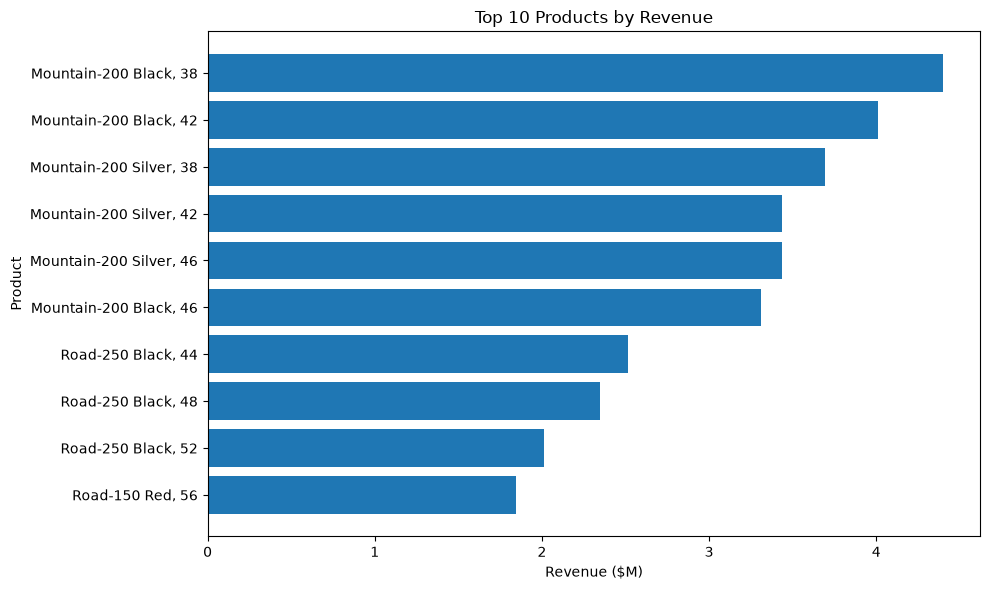

In [19]:
top_10_products = df_products.head(10).copy()
top_10_revenue = top_10_products["Revenue"].sum()
top_10_revenue_share = top_10_products["RevenueShare"].sum()
print(f"Top 10 product revenue: ${top_10_revenue:,.2f}")
print(f"Top 10 product revenue share: {top_10_revenue_share:.2f}%")

plt.figure(figsize=(10, 6))
plt.barh(top_10_products["ProductName"], top_10_products["Revenue"] / 1_000_000)
plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue ($M)")
plt.ylabel("Product")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### 5.1 Product categories

In [20]:
df_categories = (
    df_order_lines.groupby("Category")
    .agg(UnitsSold=("OrderQty", "sum"), Revenue=("LineTotal", "sum"))
    .reset_index()
    .sort_values("Revenue", ascending=False)
    .reset_index(drop=True)
)
df_categories["RevenueShare"] = 100 * df_categories["Revenue"] / df_categories["Revenue"].sum()
df_categories

,Category,UnitsSold,Revenue,RevenueShare
0,Bikes,90268,9.465117e+07,86.166855
1,Components,49044,1.180259e+07,10.744635
2,Clothing,73670,2.120543e+06,1.930462
3,Accessories,61932,1.272073e+06,1.158047


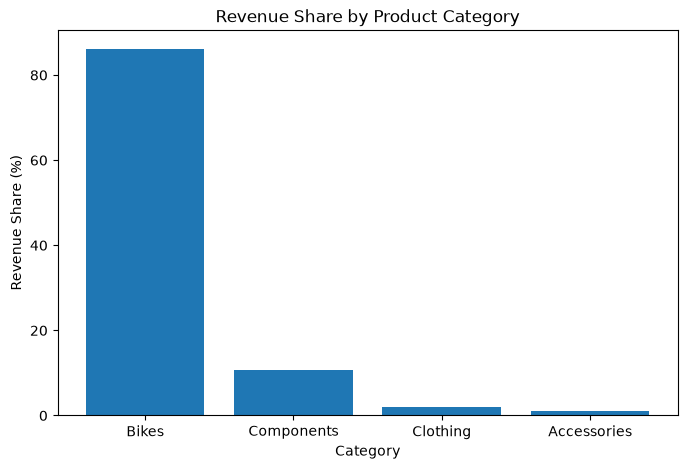

In [21]:
plt.figure(figsize=(8, 5))

plt.bar(
    df_categories["Category"],
    df_categories["RevenueShare"]
)

plt.title("Revenue Share by Product Category")
plt.xlabel("Category")
plt.ylabel("Revenue Share (%)")

plt.show()

### 5.2 Bike subcategories

In [22]:
df_bike_subcategories = (
    df_order_lines[df_order_lines["Category"] == "Bikes"]
    .groupby("Subcategory")
    .agg(UnitsSold=("OrderQty", "sum"), Revenue=("LineTotal", "sum"))
    .reset_index()
    .sort_values("Revenue", ascending=False)
    .reset_index(drop=True)
)
df_bike_subcategories["RevenueShare"] = (
    100 * df_bike_subcategories["Revenue"] / df_bike_subcategories["Revenue"].sum()
)
df_bike_subcategories["AverageRevenuePerUnit"] = (
    df_bike_subcategories["Revenue"] / df_bike_subcategories["UnitsSold"]
)
df_bike_subcategories

,Subcategory,UnitsSold,Revenue,RevenueShare,AverageRevenuePerUnit
0,Road Bikes,47196,4.390944e+07,46.390801,930.363537
1,Mountain Bikes,28321,3.644544e+07,38.505010,1286.869953
2,Touring Bikes,14751,1.429629e+07,15.104188,969.174379


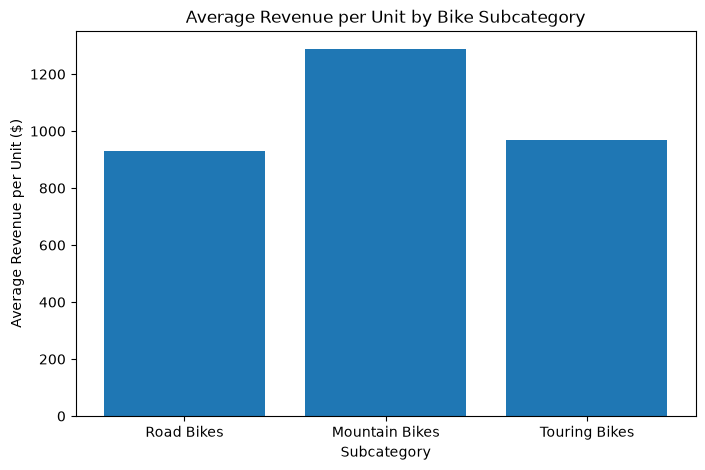

In [23]:
plt.figure(figsize=(8, 5))

plt.bar(
    df_bike_subcategories["Subcategory"],
    df_bike_subcategories["AverageRevenuePerUnit"]
)

plt.title("Average Revenue per Unit by Bike Subcategory")
plt.xlabel("Subcategory")
plt.ylabel("Average Revenue per Unit ($)")

plt.show()

**Product findings:** Bikes contribute **86.17%** of line-item revenue. Within Bikes, Road Bikes account for **46.39%**, followed by Mountain Bikes (**38.51%**); Mountain Bikes have the highest realized revenue per unit among these three subcategories. The Top 10 products represent **28.23%** of product-line revenue. *Average revenue per unit is not the same as list price or profit margin.*

## 6. Customer Analysis

A customer with a `StoreID` is classified as **Store**, even if it also has a `PersonID` (often a contact). The original SQL-only customer aggregation has been removed in favor of the single customer-order extract and Pandas aggregations above.

In [24]:
df_customer_type_summary = (
    df_customer_orders.groupby("CustomerType")
    .agg(
        NumberOfCustomers=("CustomerID", "nunique"),
        NumberOfOrders=("SalesOrderID", "nunique"),
        Revenue=("TotalDue", "sum"),
    )
    .reset_index()
)
df_customer_type_summary["AverageOrderValue"] = (
    df_customer_type_summary["Revenue"] / df_customer_type_summary["NumberOfOrders"]
)
df_customer_type_summary["RevenueShare"] = (
    100 * df_customer_type_summary["Revenue"] / df_customer_type_summary["Revenue"].sum()
)
df_customer_type_summary["OrdersPerCustomer"] = (
    df_customer_type_summary["NumberOfOrders"] / df_customer_type_summary["NumberOfCustomers"]
)
df_customer_type_summary["RevenuePerCustomer"] = (
    df_customer_type_summary["Revenue"] / df_customer_type_summary["NumberOfCustomers"]
)
df_customer_type_summary

,CustomerType,NumberOfCustomers,NumberOfOrders,Revenue,AverageOrderValue,RevenueShare,OrdersPerCustomer,RevenuePerCustomer
0,Person,18484,27659,3.244134e+07,1172.903544,26.328668,1.496375,1755.103826
1,Store,635,3806,9.077545e+07,23850.616656,73.671332,5.993701,142953.459832


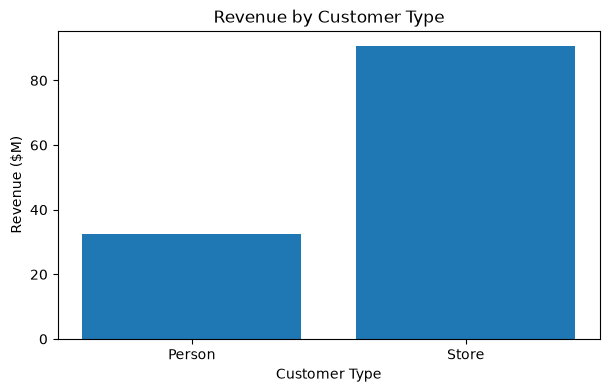

In [25]:
plt.figure(figsize=(7, 4))
plt.bar(df_customer_type_summary["CustomerType"], df_customer_type_summary["Revenue"] / 1_000_000)
plt.title("Revenue by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Revenue ($M)")
plt.show()

In [26]:
df_top_customers = df_customers.sort_values("Revenue", ascending=False).reset_index(drop=True)
top_10_customer_revenue = df_top_customers.head(10)["Revenue"].sum()
total_customer_revenue = df_customers["Revenue"].sum()
top_10_customer_share = 100 * top_10_customer_revenue / total_customer_revenue

print(f"Top 10 Customer Revenue: ${top_10_customer_revenue:,.2f}")
print(f"Top 10 Revenue Share: {top_10_customer_share:.2f}%")
df_top_customers.head(10)

Top 10 Customer Revenue: $8,934,178.74
Top 10 Revenue Share: 7.25%


,CustomerID,CustomerType,CustomerName,NumberOfOrders,Revenue,AverageOrderValue,FirstOrderDate,LastOrderDate
0,29818,Store,Brakes and Gears,12,989184.0820,82432.006833,2011-07-01,2014-03-31
1,29715,Store,Excellent Riding Supplies,12,961675.8596,80139.654967,2011-08-01,2014-05-01
2,29722,Store,Vigorous Exercise Company,12,954021.9235,79501.826958,2011-08-01,2014-05-01
3,30117,Store,Totes & Baskets Company,12,919801.8188,76650.151567,2011-07-01,2014-03-31
4,29614,Store,Retail Mall,12,901346.8560,75112.238000,2011-05-31,2014-03-01
5,29639,Store,Corner Bicycle Supply,12,887090.4106,73924.200883,2011-08-01,2014-05-01
6,29701,Store,Outdoor Equipment Store,8,841866.5522,105233.319025,2012-07-31,2014-05-01
7,29617,Store,Thorough Parts and Repair Services,12,834475.9271,69539.660592,2011-07-01,2014-03-31
8,29994,Store,"Health Spa, Limited",12,824331.7682,68694.314017,2011-05-31,2014-03-01
9,29646,Store,Fitness Toy Store,12,820383.5466,68365.295550,2011-05-31,2014-03-01


**Customer findings:** **18,484 Person customers** and **635 Store customers** appear in the sales records. Stores generate **73.67% of order revenue**, buy more often, and have substantially larger orders. The Top 10 customers contribute **7.25%** of total header-level revenue. A top-10 concentration statistic alone is not a complete measure of customer dependency.

## 7. Geographic Analysis

Aggregate geography using order-header revenue (`TotalDue`), first by region and then by sales territory.

In [27]:
df_region_summary = (
    df_geography.groupby("Region")
    .agg(
        NumberOfOrders=("SalesOrderID", "nunique"),
        Revenue=("TotalDue", "sum"),
        AverageOrderValue=("TotalDue", "mean"),
    )
    .reset_index()
    .sort_values("Revenue", ascending=False)
    .reset_index(drop=True)
)
df_region_summary["RevenueShare"] = (
    100 * df_region_summary["Revenue"] / df_region_summary["Revenue"].sum()
)
df_region_summary

,Region,NumberOfOrders,Revenue,AverageOrderValue,RevenueShare
0,North America,16108,8.922879e+07,5539.408517,72.416101
1,Europe,8514,2.217362e+07,2604.371345,17.995614
2,Pacific,6843,1.181438e+07,1726.490734,9.588285


In [28]:
df_territory_summary = (
    df_geography.groupby(["Territory", "Region"])
    .agg(
        NumberOfOrders=("SalesOrderID", "nunique"),
        Revenue=("TotalDue", "sum"),
        AverageOrderValue=("TotalDue", "mean"),
    )
    .reset_index()
    .sort_values("Revenue", ascending=False)
    .reset_index(drop=True)
)
df_territory_summary["RevenueShare"] = (
    100 * df_territory_summary["Revenue"] / df_territory_summary["Revenue"].sum()
)
df_territory_summary

,Territory,Region,NumberOfOrders,Revenue,AverageOrderValue,RevenueShare
0,Southwest,North America,6224,2.715059e+07,4362.242061,22.034818
1,Canada,North America,4067,1.839893e+07,4523.956033,14.932161
2,Northwest,North America,4594,1.806166e+07,3931.576049,14.658441
3,Australia,Pacific,6843,1.181438e+07,1726.490734,9.588285
4,Central,North America,385,8.913299e+06,23151.426616,7.233835
5,Southeast,North America,486,8.884099e+06,18280.039850,7.210137
6,United Kingdom,Europe,3219,8.574049e+06,2663.575243,6.958507
7,France,Europe,2672,8.119749e+06,3038.828348,6.589808
8,Northeast,North America,352,7.820210e+06,22216.504626,6.346708
9,Germany,Europe,2623,5.479820e+06,2089.142042,4.447300


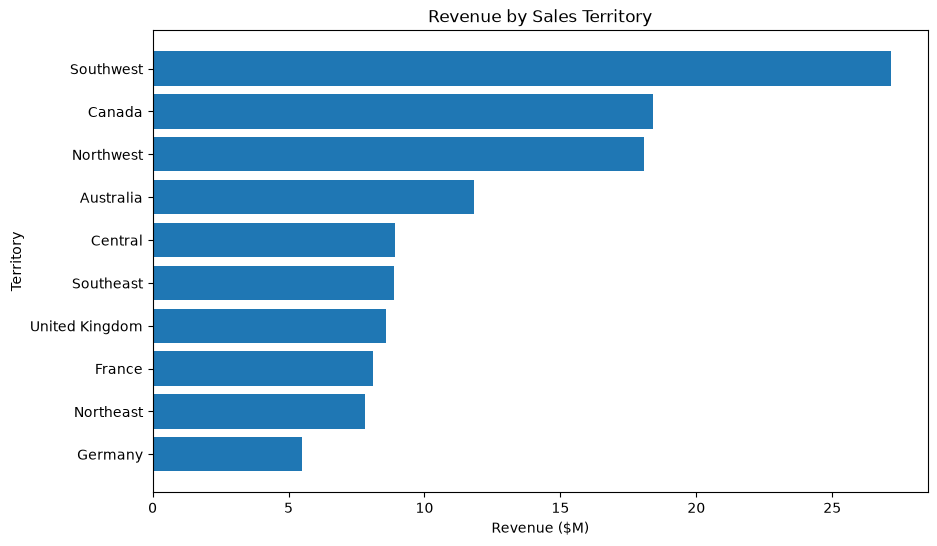

In [29]:
plt.figure(figsize=(10, 6))

plt.barh(
    df_territory_summary["Territory"],
    df_territory_summary["Revenue"] / 1_000_000
)

plt.title("Revenue by Sales Territory")
plt.xlabel("Revenue ($M)")
plt.ylabel("Territory")

plt.gca().invert_yaxis()

plt.show()

**Geographic findings:** North America accounts for **72.42%** of order revenue. **Southwest** leads territories at **22.03%**. The high average order values in Central, Southeast, and Northeast are **consistent with** the strong business-customer segment, but the geographic table alone does not establish the segment mix within each territory.

## 8. Key Business Insights

**Sales performance.** For comparable **January–May** periods, revenue increased **46.46%** from 2013 to 2014, with orders increasing **435.21%** and average order value decreasing **72.64%**. Comparing full 2013 against partial 2014 would be misleading.

**June 2014 mix shift.** June has 939 orders but only around **$54K in header-level revenue**. No non-online orders appear, and all sold products in the extracted order lines are Accessories or Clothing. This establishes the composition shift, **not its underlying cause**.

**Products.** Bikes provide **86.17%** of line-item revenue. Road Bikes lead Bike-category revenue, while Mountain Bikes earn more on average per unit. The ten highest-revenue products account for **28.23%** of product revenue.

**Customers.** Stores are **635 of 19,119** customers with sales yet produce **73.67%** of header-level revenue. The Top 10 customers produce **7.25%** of revenue.

**Geography.** North America accounts for **72.42%** of header-level revenue; Southwest is the largest territory at **22.03%**.

**Suggested next analysis:** compare 2013 and 2014 on a monthly matched-period basis by customer type and category, and use Power BI to make these patterns interactive.

## 9. Limitations and Metric Definitions

- **Incomplete years:** The dataset covers **May 31, 2011–June 30, 2014**. Neither 2011 nor 2014 is a complete calendar year.
- **June anomaly:** June 2014 has an unusual distribution of order types and product categories. Without transaction-system or business-process context, we cannot claim whether this represents a genuine commercial shift or dataset-generation effects.
- **Different revenue grains:** `SalesOrderHeader.TotalDue` is an **order-level total**, whereas `SalesOrderDetail.LineTotal` is **line-level product revenue**. These measures should be kept separate; taxes, freight, and other order-level components affect reconciliation.
- **Customer scope:** Customer counts are based on **customers with recorded sales**, not every customer in the Customer dimension.
- **No profitability analysis:** Neither net profit nor product margins have been calculated from these revenue-only summaries.
- **Sample data:** AdventureWorks is fictional; these are portfolio analytics findings, not evidence of a real company's operations.